![The Bridge - Matplotlib](../img/banner_thebridge_matplotlib.png)

# Visualización con Matplotlib: Subplots

En análisis de datos **muchas veces es útil comparar diferentes vistas de datos lado a lado.**
Para este fin, Matplotlib tiene el concepto de *subplots*: grupos de ejes más pequeños que pueden existir juntos dentro de una sola figura.
Estos subplots podrían ser inserciones, cuadrículas de gráficos u otros diseños más complicados y además no tienen por qué ser del mismo tipo.  

En esta sección exploraremos cómo crear subplots en Matplotlib.

Importamos como siempre:

In [1]:
# %matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-white')
import numpy as np


### "A mano"

El método más básico para crear un eje es usar la función ``plt.axes``.
Como hemos visto anteriormente, de forma predeterminada esto crea un objeto de eje estándar que llena toda la figura.
``plt.axes`` también toma un argumento opcional que es una lista de cuatro números en el sistema de coordenadas de la figura.
Estos números representan ``[izquierda, inferior, ancho, altura]`` en el sistema de coordenadas de la figura, que varía de 0 en la esquina inferior izquierda de la figura a 1 en la esquina superior derecha de la figura.

Por ejemplo, podríamos crear un eje secundario en la esquina superior derecha de otro eje estableciendo la posición *x* e *y* en 0.65 (es decir, comenzando en el 65% del ancho y el 65% de la altura de la figura) y las extensiones *x* e *y* en 0.2 (es decir, el tamaño del eje es el 20% del ancho y el 20% de la altura de la figura):


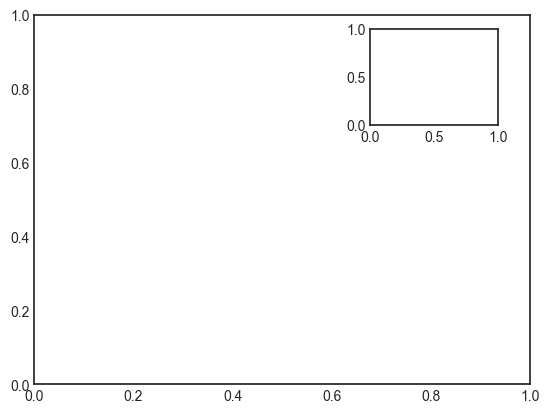

In [2]:
ax1 = plt.axes()
ax2 = plt.axes([0.65, 0.65, 0.2, 0.2])

El equivalente de este comando dentro de la interfaz orientada a objetos es ``fig.add_axes()``. Usemos esto para crear dos ejes apilados verticalmente:

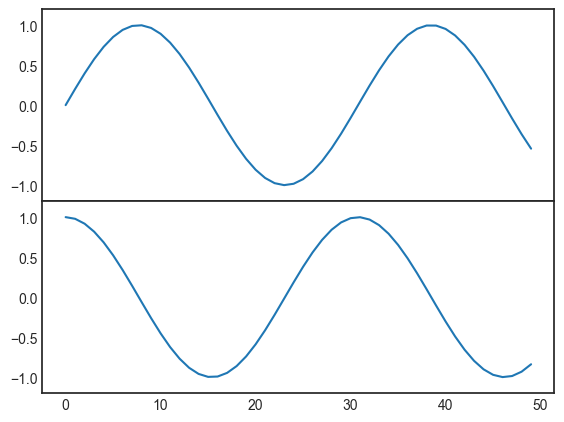

In [3]:
fig = plt.figure()
ax1 = fig.add_axes([0.1, 0.5, 0.8, 0.4],
                   xticklabels=[], ylim=(-1.2, 1.2))
ax2 = fig.add_axes([0.1, 0.1, 0.8, 0.4],
                   ylim=(-1.2, 1.2))

x = np.linspace(0, 10)
ax1.plot(np.sin(x))
ax2.plot(np.cos(x));

Ahora tenemos dos ejes (el superior sin etiquetas en el eje x) que justo se tocan: la parte inferior del panel superior (en la posición 0.5) coincide con la parte superior del panel inferior (en la posición 0.1 + 0.4).


### Con cuadrículas sencillas

Las columnas o filas alineadas de *subplots* o gráficas formando cuadrículas o matrices son una necesidad lo suficientemente común como para que Matplotlib tenga varias rutinas de conveniencia que las hacen fáciles de crear.

El nivel más bajo de estas es ``plt.subplot()``, este comando tiene tres argumentos enteros: el número de filas, el número de columnas y el índice de la gráfica que se creará en este esquema, que va desde la esquina superior izquierda hasta la esquina inferior derecha.


Vamos a crear una figura con una matriz de subplots o gráficas de 2x3, y las numeraremos con su índice para que te quede más claro:

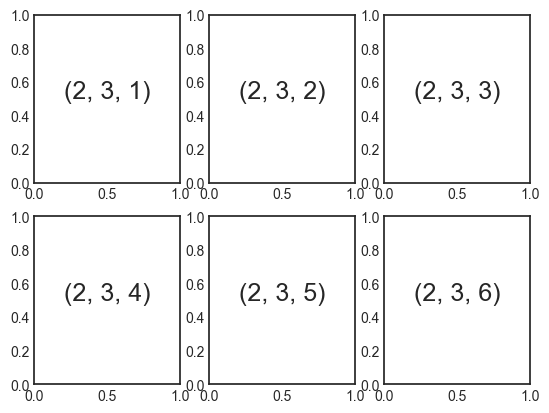

In [4]:
for i in range(1, 7):
    plt.subplot(2, 3, i)
    plt.text(0.5, 0.5, str((2, 3, i)),
             fontsize=18, ha='center')

El comando ``plt.subplots_adjust`` se puede usar para ajustar el espaciado entre estos gráficos.
El siguiente código utiliza el comando orientado a objetos equivalente, ``fig.add_subplot()``:

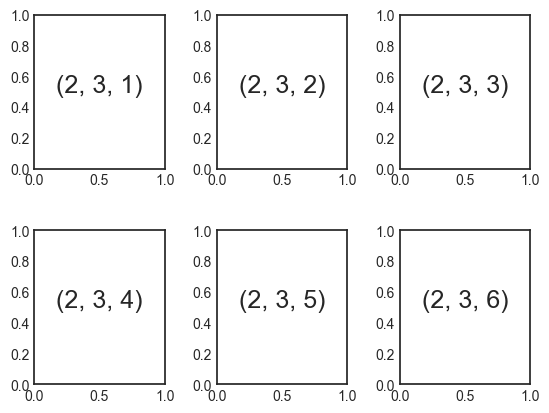

In [5]:
fig = plt.figure()
fig.subplots_adjust(hspace=0.4, wspace=0.4)

for i in range(1, 7):
    ax = fig.add_subplot(2, 3, i)
    ax.text(0.5, 0.5, str((2, 3, i)),
            fontsize=18, ha='center')

Hemos utilizado los argumentos ``hspace`` y ``wspace`` de ``plt.subplots_adjust``, que especifican el **espaciado a lo largo de la altura y anchura de la figura**, en unidades del tamaño del subtrazado (en este caso, el espacio es el 40% de la anchura y altura del subtrazado).

### La cuadrícula completa de una vez

**La aproximación anterior puede volverse bastante tediosa si queremos crear una cuadrícula o matriz grande, especialmente si se desea ocultar las etiquetas de los ejes x e y en los gráficos interiores.**  

Para este propósito, ``plt.subplots()`` es la herramienta más fácil de usar (fíjate en la ``s`` al final de ``subplots``). En lugar de crear una sola subtrama, esta función crea una cuadrícula completa de subtramas en una sola línea, devolviéndolas en un array de NumPy.
Los argumentos son el número de filas y el número de columnas, junto con palabras clave opcionales ``sharex`` y ``sharey``, que permiten especificar las relaciones entre diferentes ejes.  


Aquí crearemos una cuadrícula de $2 \times 3$ subtramas, donde todos los ejes en la misma fila comparten su escala en el eje y, y todos los ejes en la misma columna comparten su escala en el eje x:

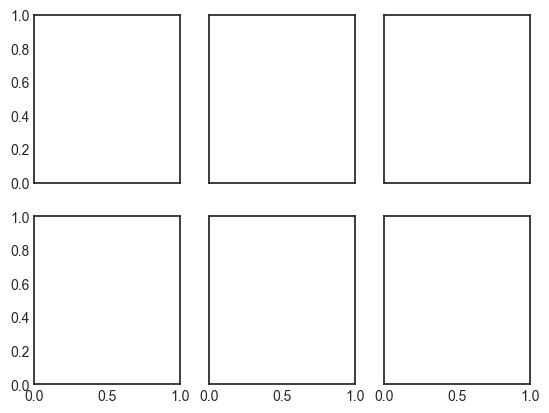

In [6]:
fig, ax = plt.subplots(2, 3, sharex='col', sharey='row')

Fíjate que al especificar ``sharex`` y ``sharey`` se han eliminado automáticamente las etiquetas interiores de la cuadrícula, lo que deja el gráfico más limpio. Los ejes se devuelven en un array de NumPy, así que podemos acceder a cada uno con la notación de índices habitual:

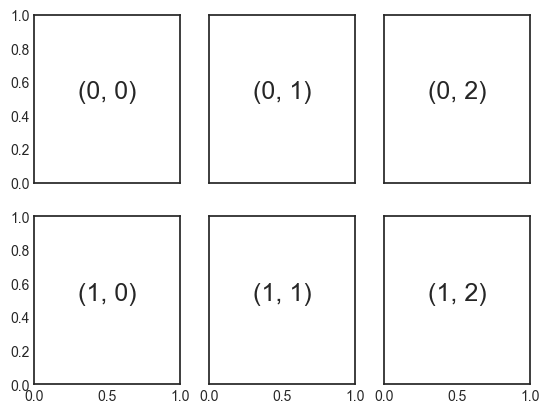

In [7]:
# Los axes están en un array bidimensional accedido por [fila,columna] tipo python, empezando en cero
for i in range(2):
    for j in range(3):
        ax[i, j].text(0.5, 0.5, str((i, j)),
                      fontsize=18, ha='center')
fig

Si queremos acceder a cualquiera de los gráficos podemos acceder a partir del elemento del array de objetos en "ax" (tal como hemos añadido los textos):

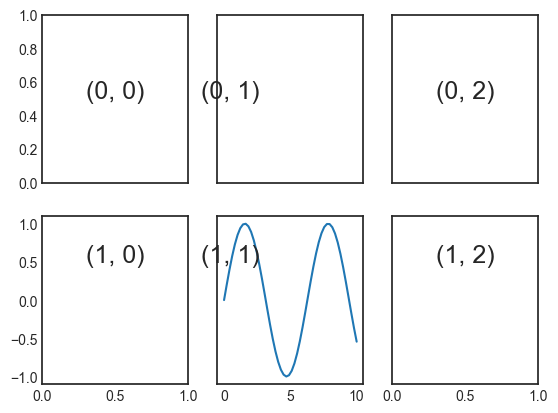

In [8]:
ax[1, 1].plot(x, np.sin(x))
fig

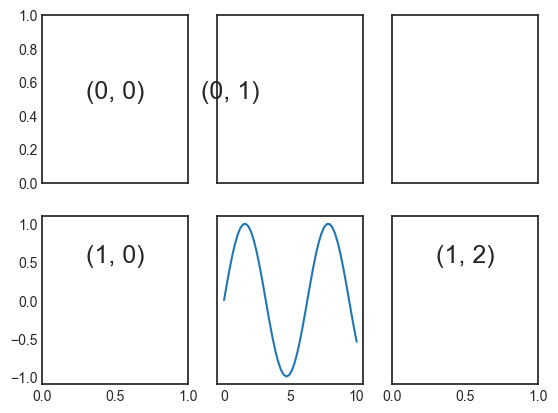

In [9]:
# Te dejo aquí cómo haríamos para quitar el texto:
fig, ax = plt.subplots(2, 3, sharex = "col", sharey = "row")
textos = np.full(fill_value= None, shape= ax.shape)
for i in range(2):
    for j in range(3):  
        textos[i,j] = ax[i, j].text(0.5, 0.5, str((i, j)),
                      fontsize=18, ha='center')
textos[0,2].remove()
textos[1,1].remove()
ax[1,1].plot(x,np.sin(x));


### Disposiciones más complejas con ``plt.GridSpec``

Para ir más allá de una cuadrícula regular y tener gráficos que ocupen varias filas o columnas, la mejor herramienta es ``plt.GridSpec()``.
El objeto ``plt.GridSpec()`` no crea ningún gráfico por sí mismo; es simplemente una interfaz que entiende el comando ``plt.subplot()``.
Por ejemplo, un *gridspec* de dos filas y tres columnas con un espaciado determinado se define así:

In [10]:
grid = plt.GridSpec(2, 3, wspace=0.4, hspace=0.3)

A partir de aquí indicamos la posición y la extensión de cada gráfico con la sintaxis de *slicing* de Python que ya conoces:

```text
+--------+-----------------------+
| [0,0]  |        [0,1:]         |
+--------+-----------+-----------+
|      [1,:2]        |   [1,2]   |
+--------------------+-----------+
```

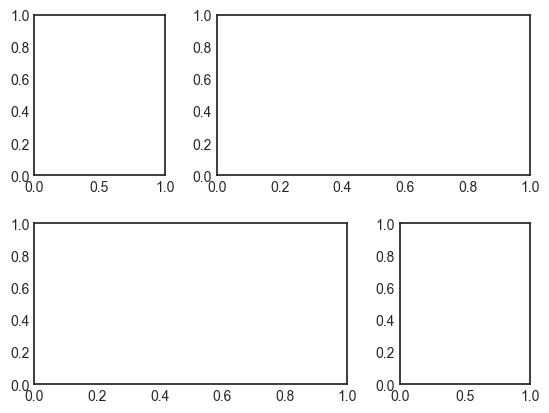

In [11]:
plt.subplot(grid[0, 0])
plt.subplot(grid[0, 1:])
plt.subplot(grid[1, :2])
plt.subplot(grid[1, 2]);

Este tipo de cuadrícula flexible tiene muchos usos. Uno muy habitual en análisis de datos es acompañar un diagrama de dispersión con los histogramas de cada variable en los márgenes:

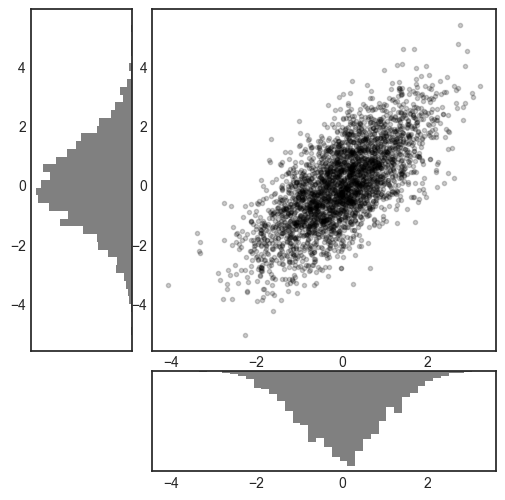

In [12]:
# Generamos datos con distribución normal
mean = [0, 0]
cov = [[1, 1], [1, 2]]
x, y = np.random.multivariate_normal(mean, cov, 3000).T

# Preparamos los ejes con gridspec
fig = plt.figure(figsize=(6, 6))
grid = plt.GridSpec(4, 4, hspace=0.2, wspace=0.2)
main_ax = fig.add_subplot(grid[:-1, 1:])
y_hist = fig.add_subplot(grid[:-1, 0], xticklabels=[], sharey=main_ax)
x_hist = fig.add_subplot(grid[-1, 1:], yticklabels=[], sharex=main_ax)

# Puntos de dispersión en el eje principal
main_ax.plot(x, y, 'ok', markersize=3, alpha=0.2)

# Histogramas en los ejes de los márgenes
x_hist.hist(x, 40, histtype='stepfilled',
            orientation='vertical', color='gray')
x_hist.invert_yaxis()

y_hist.hist(y, 40, histtype='stepfilled',
            orientation='horizontal', color='gray')
y_hist.invert_xaxis()